# Beyond the state of the art: the leakage-safe protocol per case, with gates

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 02 to 05 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state the leakage-safe protocol of Contraste, the six rules it enforces and the split each of the three credit-scoring cases declares;
- check, on the committed artifacts of C01, C02 and C03, the properties that the protocol's gates guarantee: transforms fitted on the training slice only, a calibration map fitted on its own slice, flags that refuse an out-of-time claim, and a target read only where it is observable;
- say what a leak looks like to the engine's tests, with a planted leak of known size (C22), and why the tests see it as a drop in discrimination out of time and not as a drift of the leaked feature;
- state exactly what the claim BS-3 says and what it does not: enforcement of known rules by gates, not a new method.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The notebook reads the evidence that the claim BS-3 lists, and nothing else:

- the requirements and the gates: `docs/design/features/c01-retail-pd/requirements.md` (the EARS requirements CT-101 to CT-103 with the test that fails when each is violated). The gates themselves are in `tests/test_leakage.py`; running them needs the pipeline libraries, which the notebook environment does not carry;
- the declared split of each case, as committed: `data/derived/C01/models-taiwan.json`, `data/derived/C02/h1.json` to `h5.json` and `pooled.json`, `data/derived/C03/fy2015-17.json`, `fy2018-20.json` and `models-sba-7a.json`;
- the planted leak of case C22: `data/derived/C22/leakage.json`, synthetic with a known truth (no third-party licence; generated by the engine from a seed).

The real data behind C01, C02 and C03 are UCI Taiwan (https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), UCI Polish companies (https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data) and the SBA 7(a) FOIA file (https://data.sba.gov/dataset/7a-504-foia), all licence class `mirror-allowed`. The next cell loads the files.

In [2]:
# Load the committed evidence of the claim
ROOT = Path("../../..").resolve()
read = lambda rel: json.loads((ROOT / "data" / "derived" / rel).read_text(encoding="utf-8"))
c01 = read("C01/models-taiwan.json")
c01_holdout = read("C01/holdout.json")
c02 = {h: read(f"C02/{h}.json") for h in ("h1", "h2", "h3", "h4", "h5", "pooled")}
c03_models = read("C03/models-sba-7a.json")
c03 = {n: read(f"C03/{n}.json") for n in ("fy2015-17", "fy2018-20")}
c22 = read("C22/leakage.json")
requirements = (ROOT / "docs" / "design" / "features" / "c01-retail-pd" / "requirements.md").read_text(encoding="utf-8")

LANG = "en"


def check(label, ok):
    # Print one property and stop the notebook if it does not hold
    print(f"{'holds' if ok else 'FAILS':>10s}  {label}")
    assert ok


print("baked by riskvalidation", sorted({c01["provenance"]["riskvalidation_version"], c03_models["provenance"]["riskvalidation_version"], c02["h1"]["provenance"]["riskvalidation_version"]}), "| installed", rv.__version__)


baked by riskvalidation ['0.4.3', '0.5.0', '0.9.0'] | installed 0.9.0


## Method

### Step 1: the rules, the requirements and the gates

The research basis of the product (dossier 04, "universal leakage rules") states six rules for every scoring pipeline:

1. every feature is computed from information available at the observation date, and the performance window starts after it;
2. binning, WoE, imputation, scaling and feature selection are fitted on the training slice only;
3. calibration maps are fitted on a separate calibration slice, never on the test slice;
4. nothing is resampled before calibration is measured;
5. for loss given default and credit conversion factors, the training set holds only defaults whose workout or reference window closed before the training cut-off;
6. macro covariates enter with the lag that would have been available in real time.

Rules 1 to 4 apply to the scoring cases (rules 5 and 6 belong to topics 05 and 12). What the product adds is the second half of each rule: a requirement in the EARS form (Mavin et al., 2009, https://doi.org/10.1109/RE.2009.9) that names **the gate that fails when the rule is violated**. The next cell reads the requirements CT-101 to CT-103 from the case's requirements file and the gate that each one names.

In [3]:
# Read the requirements CT-101 to CT-103 and the gate that each one names
wording = {
    "CT-101": "THE split stage SHALL fit binning, WoE, imputation and scaling on the training slice only.",
    "CT-102": "THE calibration map SHALL be fitted on a calibration slice disjoint from the test slice.",
    "CT-103": "IF a value outside the training information set is perturbed (a holdout label, or a value dated after the observation date), THEN every fitted parameter SHALL be unchanged.",
}
for line in requirements.splitlines():
    cells_ = [c.strip() for c in line.strip().strip("|").split("|")]
    if cells_ and re.fullmatch(r"CT-10[123]", cells_[0]):
        print(cells_[0], "|", wording[cells_[0]])
        print("        gate:", cells_[2])
gate_names = [re.search(r"::(test_\w+)", line).group(1) for line in requirements.splitlines() if re.match(r"\|\s*CT-10[123]\s*\|", line)]
check("each of the three requirements names its own gate: " + ", ".join(gate_names), len(set(gate_names)) == 3)


CT-101 | THE split stage SHALL fit binning, WoE, imputation and scaling on the training slice only.
        gate: `tests/test_leakage.py::test_fitted_transforms_train_only`
CT-102 | THE calibration map SHALL be fitted on a calibration slice disjoint from the test slice.
        gate: `tests/test_leakage.py::test_calibration_slice_disjoint`
CT-103 | IF a value outside the training information set is perturbed (a holdout label, or a value dated after the observation date), THEN every fitted parameter SHALL be unchanged.
        gate: `tests/test_leakage.py::test_outside_information_perturbation_invariance`
     holds  each of the three requirements names its own gate: test_fitted_transforms_train_only, test_calibration_slice_disjoint, test_outside_information_perturbation_invariance


The gate file `tests/test_leakage.py` runs the case's own fitting path twice: once on a planted data set and once with everything **outside the training information** changed (the holdout's labels and inputs and the calibration slice's inputs). A fitted parameter that changes between the two runs read something it must not have. The three gates passed when the evidence of this claim was assembled (`python -m pytest tests/test_leakage.py`: 3 passed, in the pipeline environment, which the notebook environment does not replicate). The notebook cannot run them, so the next steps check, on the committed artifacts, the properties that the gates guarantee.

### Step 2: C01, a locked holdout

C01 declares a stratified split of 30,000 cards into a training slice, a calibration slice and a locked holdout of 30% (the SDD table of leakage-safe splits). The properties that follow from CT-101 and CT-102 can be read from the committed artifact: the slices partition the file, the counts behind every binned variable add up to the training slice alone (so the holdout never entered the binning), each calibration map was fitted on the calibration slice, and the holdout of the artifact is the holdout of the split.

In [4]:
# Check the properties of the C01 split on the committed artifact
split = c01["fit"]["split"]
parts = [split[k]["n"] for k in ("train", "calibration", "holdout")]
check("the three slices add up to the 30000 cards of the file: " + " + ".join(str(p) for p in parts), sum(parts) == 30000)
check("the training slice is the one the fit used: " + str(c01["fit"]["train_rows"]), c01["fit"]["train_rows"] == split["train"]["n"])
card = next(m for m in c01["model"] if m["id"] == "P1-scorecard")["details"]
sums = {name: sum(r["count"] for r in card["points_table"] if r["feature"] == name) for name in card["features"]}
check("the counts behind each of the 13 binned variables add up to the training slice alone", set(sums.values()) == {split["train"]["n"]})
maps = [(m["id"], m["calibration"]["fitted_on"]) for m in c01["model"] if m["calibration"] is not None]
check("every calibration map was fitted on the calibration slice: " + ", ".join(i for i, _ in maps), all(f == "calibration slice" for _, f in maps))
check("the holdout of the artifact has the size of the holdout of the split: " + str(c01_holdout["outputs"]["n"]), c01_holdout["outputs"]["n"] == split["holdout"]["n"])
rates = [split[k]["default_rate"] for k in ("train", "calibration", "holdout")]
check("the slices are stratified: the default rates agree to four decimals", max(rates) - min(rates) < 1e-4)


     holds  the three slices add up to the 30000 cards of the file: 16800 + 4200 + 9000
     holds  the training slice is the one the fit used: 16800
     holds  the counts behind each of the 13 binned variables add up to the training slice alone
     holds  every calibration map was fitted on the calibration slice: P3-ebm, P4-lightgbm, P4-xgboost
     holds  the holdout of the artifact has the size of the holdout of the split: 9000
     holds  the slices are stratified: the default rates agree to four decimals


### Step 3: C02, flags that refuse a claim

C02 has files with no date and no company identifier, so its protocol is a locked, stratified holdout within each file, and **it refuses the claims the data cannot support**. Four flags are committed in the split block of every horizon and of the pooled file: the fit uses the training slice only, the calibration map has its own slice, nothing is resampled before calibration, and no out-of-time claim is made. The next cell checks the four flags and the partition of the rows for the five horizons and the pooled file.

In [5]:
# Check the four flags and the partition of the rows in the six C02 files
for h, doc in c02.items():
    o = doc["outputs"]
    s = o["split"]
    flags = (s["fit_on_training_slice_only"], s["calibration_map_on_separate_slice"], not s["resampling_before_calibration"], not s["out_of_time_claim"])
    partition = s["train_rows"] + s["calibration_rows"] + s["holdout_rows"] == o["counts"]["rows"]
    check(f"{h:7s} flags {flags} | rows {s['train_rows']} + {s['calibration_rows']} + {s['holdout_rows']} = {o['counts']['rows']}", all(flags) and partition)
print()
print("pooled file, the committed caveat:", c02["pooled"]["outputs"]["firm_overlap_caveat"][LANG])


     holds  h1      flags (True, True, True, True) | rows 3309 + 828 + 1773 = 5910
     holds  h2      flags (True, True, True, True) | rows 5483 + 1371 + 2938 = 9792
     holds  h3      flags (True, True, True, True) | rows 5881 + 1471 + 3151 = 10503
     holds  h4      flags (True, True, True, True) | rows 5696 + 1425 + 3052 = 10173
     holds  h5      flags (True, True, True, True) | rows 3934 + 984 + 2109 = 7027
     holds  pooled  flags (True, True, True, True) | rows 24303 + 6079 + 13023 = 43405

pooled file, the committed caveat: The five files are stacked with a horizon indicator. The UCI page gives no firm identifier and no date, so whether a company appears in several files is unknown (UNVERIFIED, 08 l.855-856). No feature vector is shared by two files, but a company's ratios change from year to year, so that is not evidence that firms do not repeat. A pooled score may therefore be flattered by repeated firms.


### Step 4: C03, a target read only where it is observable

C03 is the one case with dates, and its protocol is out of time: the training window closes on the 5-year mark of its last approval year, before the test cohort starts, and the target of a vintage is read only at its own 5-year mark (notebook 04). That rule also bounds the data: a vintage can be tested only once its 5-year mark has passed on the date of the file. The next cell checks, for the two latest cohorts, that every vintage's mark is on or before the date of the file, that each training window closes before its test cohort starts, and computes the last approval year that can be tested. The year after it cannot, and the design stops there instead of reading a target that is not yet observable.

In [6]:
# Check the observability of the target and the training windows of the two latest C03 cohorts
as_of = date.fromisoformat(c03_models["fit"]["data_status"]["files_as_of"])
print("date of the SBA file:", as_of.isoformat())
for name, doc in c03.items():
    o = doc["outputs"]
    marks = [(v["fiscal_year"], date.fromisoformat(v["five_year_mark_date"]), v["mark_observed"], v["n_exempt_censored"]) for v in o["vintage_summary"]["rows"]]
    check(f"{o['cohort']['label'][LANG]}: every 5-year mark is on or before the date of the file (" + ", ".join(f"FY{fy} {m.isoformat()}" for fy, m, _, _ in marks) + ")", all(m <= as_of and obs and cens == 0 for _, m, obs, cens in marks))
    train = o["training"]
    first_approval = date(o["cohort"]["first_fy"] - 1, 10, 1)
    check(f"{o['cohort']['label'][LANG]}: the training window closes on {train['cutoff_date']}, before the first approval of the test cohort ({first_approval.isoformat()})", date.fromisoformat(train["cutoff_date"]) < first_approval)
last_testable = max(fy for fy in range(1991, 2031) if date(fy + 5, 9, 30) <= as_of)
print("last approval year whose 5-year mark has passed: FY" + str(last_testable), "| the next one reaches its mark on", date(last_testable + 6, 9, 30).isoformat())
check("the last cohort of the design ends at that year: FY" + str(c03["fy2018-20"]["outputs"]["cohort"]["last_fy"]), c03["fy2018-20"]["outputs"]["cohort"]["last_fy"] == last_testable)


date of the SBA file: 2026-06-30
     holds  FY2015-17: every 5-year mark is on or before the date of the file (FY2015 2020-09-30, FY2016 2021-09-30, FY2017 2022-09-30)
     holds  FY2015-17: the training window closes on 2014-09-30, before the first approval of the test cohort (2014-10-01)
     holds  FY2018-20: every 5-year mark is on or before the date of the file (FY2018 2023-09-30, FY2019 2024-09-30, FY2020 2025-09-30)
     holds  FY2018-20: the training window closes on 2017-09-30, before the first approval of the test cohort (2017-10-01)
last approval year whose 5-year mark has passed: FY2020 | the next one reaches its mark on 2026-09-30
     holds  the last cohort of the design ends at that year: FY2020


### Step 5: what each split cannot claim

A protocol that enforces rules also has to say where they stop. The committed artifacts state the limits themselves. C01 is a single snapshot of 2005: the artifact carries the finding `F-OOT`, accepted, that no out-of-time validation is possible. C02 sets `out_of_time_claim` to false and labels its cross-file transfer exploratory. C03 is out of time but is the SBA programme, not a bank's SME book (finding `F-DATA`). The next cell prints the limits as the artifacts word them.

In [7]:
# Print the limits that the committed artifacts state for each split
f_oot = next(f for f in c01_holdout["findings"] if f["id"] == "F-OOT")
print("C01", f_oot["id"], f_oot["status"], "|", f_oot["title"][LANG])
print("C02", "out_of_time_claim =", c02["h3"]["outputs"]["split"]["out_of_time_claim"], "|", c02["h3"]["outputs"]["transfer"]["reason"][LANG])
f_data = next(f for f in c03["fy2015-17"]["findings"] if f["id"] == "F-DATA")
print("C03", f_data["id"], f_data["status"], "|", f_data["title"][LANG])


C01 F-OOT accepted | No out-of-time validation is possible: the data is a single snapshot
C02 out_of_time_claim = False | A rung fitted on the training slice of one file and scored on the holdout of another. The firm overlap across the files is unknown, so a transfer AUC may be inflated by firms that repeat; the block is exploratory and no out-of-time claim is made.
C03 F-DATA accepted | SBA 7(a) small-business loans under a federal guarantee, not a bank's SME book; no delinquency, balance or rating


## State of the art

What the research found, and where it stops:

- **The rules are known.** Dossier 04 states the six rules above for credit scoring pipelines, and the research of dossier 06 lists the leakage screens that exist in open toolkits (a label-leaking test, a sample-leaking test, a resemblance model between development and out-of-time samples).
- **The evaluation is known to matter.** Kozodoi, Lessmann, Alamgir, Moreira-Matias and Papakonstantinou (2025, https://doi.org/10.1016/j.ejor.2025.01.040) propose a framework to train and to **evaluate** credit scoring models under sampling bias, and find that addressing the bias in the evaluation has a larger business impact than in the training. How a model is evaluated is where leaks hide.
- **The practice is not enforced.** Dossier 07 names the single-split evaluation of an open toolkit as the counter-example: one split, no separate calibration slice, no statement of what the data cannot claim. The toolkits give screens to run; none gives a protocol declared per case with a gate that fails when it is broken.

The state of the art, then, is rules and screens; what is missing in what the research found is the enforcement, case by case.

## Beyond the state of the art

The claim BS-3 (section `## Beyond the state of the art` of `docs/design/SDD.md`) is this: **the leakage-safe protocol is declared per case and enforced by gates**. It is enforcement of known rules, not a new method, and it is stated only as far as the evidence goes:

- the split of each case is declared (SDD) and recorded in its committed artifact (steps 2 to 4);
- the rules are requirements with a named gate (step 1), and the gates run the fitting path with everything outside the training information changed;
- the protocol states what each split cannot claim (step 5).

The last piece of evidence is what a leak looks like to the tests, because a gate on the fitting path protects the fits of the product, while a validator facing someone else's model has only the tests. Case C22 plants a leak of known size. In the model of C22 the score is the genuine score plus one feature that **in development carries the outcome** (shifted by a leak size for defaulters) and **at decision time is noise**. The engine's generator gives the exact development AUC. The next cell draws one sample from the generator with a seed, with a leak of 1 (committed in C22 as the specimen) and with no leak (the null), and calls the engine's tests on both: the AUC of the development sample, the AUC now, the one-sided test of the AUC against development, and the characteristic stability index of the leaked feature between the two samples.

In [8]:
# Draw one seeded sample with a leak of 1 and with no leak, and call the engine's tests on both
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.validation import disc_auc, disc_auc_vs_initial, stability_csi
from riskvalidation.validation.stability import bin_counts, quantile_edges

LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
policy = rv.default_policy()
print(f"{'leak':>6s} {'AUC development':>18s} {'AUC now':>11s} {'p AUC vs development':>22s} {'light':>6s} {'p CSI':>8s} {'light':>6s}")
for leak in (0.0, 1.0):
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    sample = generator.draw(np.random.default_rng(42))
    auc_dev = disc_auc(sample["development_risk"], sample["development_defaults"], policy=policy, model_id="leak").metric
    auc_now = disc_auc(sample["risk"], sample["defaults"], policy=policy, model_id="leak").metric
    drop = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"], policy=policy, model_id="leak")
    # The ten bins are the deciles of the feature in development, fixed before the current sample is seen
    edges = quantile_edges(sample["feature_development"], 10)
    csi = stability_csi(bin_counts(sample["feature_development"], edges), bin_counts(sample["feature_current"], edges), policy=policy, model_id="leak", segment="leaked feature")
    print(f"{leak:6.1f} {auc_dev:18.4f} {auc_now:11.4f} {drop.p_value:22.3g} {LIGHT[drop.light.value]:>6s} {csi.p_value:8.3f} {LIGHT[csi.light.value]:>6s}")
truth = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=1.0).truth()
print("exact development AUC of the generator:", round(truth["auc_development"], 4), "| AUC of the genuine score now:", round(truth["auc_genuine_current"], 4))


  leak    AUC development     AUC now   p AUC vs development  light    p CSI  light
   0.0             0.6866      0.6779                  0.259  green    0.240  green
   1.0             0.8367      0.6779               3.95e-15    red    0.046  amber
exact development AUC of the generator: 0.8413 | AUC of the genuine score now: 0.7602


One sample says little; the committed C22 artifact says how often the tests see a leak. For each leak size it holds the rejection rate at 5% of 2,000 seeded repetitions of the same sample, with its Monte Carlo standard error: at leak 0 the rate is the size of the test (it should be near 0.05), and above 0 it is the power. The next cell prints the table and the figure draws the two curves.

  leak   repetitions     AUC vs development          CSI of the leaked feature
  0.00          2000          0.046 (se 0.005)          0.046 (se 0.005)
  0.25          2000          0.635 (se 0.011)          0.060 (se 0.005)
  0.50          2000          0.989 (se 0.002)          0.079 (se 0.006)
  1.00          2000          1.000 (se 0.000)          0.146 (se 0.008)
  1.50          2000          1.000 (se 0.000)          0.334 (se 0.011)
  2.00          2000          1.000 (se 0.000)          0.581 (se 0.011)


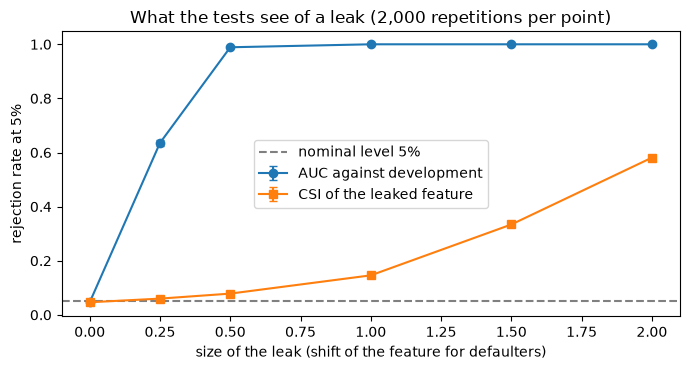

committed specimen of C22, leak 1: p AUC vs development 4.56e-16 red | p CSI 0.639 green
exact inflation of the development AUC by a leak of 1: 0.1499


In [9]:
# Read the committed rejection rates of the two tests by leak size and draw them
sims = {s["key"]: s for s in c22["outputs"]["simulations"]}
leaks = c22["outputs"]["ladder"]["values"]
rows = []
print(f"{'leak':>6s} {'repetitions':>13s} {'AUC vs development':>22s} {'CSI of the leaked feature':>34s}")
for x in leaks:
    tag = f"l{x:g}"
    a, f = sims[f"disc.auc_vs_initial@{tag}"], sims[f"stability.csi@{tag}"]
    rows.append((x, a["rates"]["p<0.05"], f["rates"]["p<0.05"]))
    print(f"{x:6.2f} {a['n_rep']:13d} {a['rates']['p<0.05']['rate']:14.3f} (se {a['rates']['p<0.05']['se']:.3f}) {f['rates']['p<0.05']['rate']:14.3f} (se {f['rates']['p<0.05']['se']:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar([r[0] for r in rows], [r[1]["rate"] for r in rows], yerr=[r[1]["se"] for r in rows], marker="o", capsize=3, label="AUC against development")
ax.errorbar([r[0] for r in rows], [r[2]["rate"] for r in rows], yerr=[r[2]["se"] for r in rows], marker="s", capsize=3, label="CSI of the leaked feature")
ax.axhline(0.05, color="gray", linestyle="--", label="nominal level 5%")
ax.set_xlabel("size of the leak (shift of the feature for defaulters)")
ax.set_ylabel("rejection rate at 5%")
ax.set_title("What the tests see of a leak (2,000 repetitions per point)")
ax.legend()
fig.tight_layout()
plt.show()
specimen = {t["test_id"]: t for t in c22["tests"]}
print("committed specimen of C22, leak 1: p AUC vs development", format(specimen["disc.auc_vs_initial"]["p_value"], ".3g"), LIGHT[specimen["disc.auc_vs_initial"]["light"]], "| p CSI", round(specimen["stability.csi"]["p_value"], 3), LIGHT[specimen["stability.csi"]["light"]])
exact_inflation = c22["impact"]["dev_auc_inflation_l1"]["value"]
print("exact inflation of the development AUC by a leak of 1:", round(exact_inflation, 4))


## Results

- **The rules are requirements with gates.** CT-101 to CT-103 each name the test that fails when it is violated, the three gates exist in `tests/test_leakage.py`, and they passed (3 passed) in the pipeline environment when this evidence was assembled. A rule written only in a dossier would be the practice of the research; these are the rules with a failing test.
- **The declared split is in the artifacts.** For C01 the three slices partition the 30,000 cards, the counts behind each of the 13 binned variables add up to the 16,800 training cards alone, every calibration map was fitted on the calibration slice, and the slices share one default rate. For the five horizons and the pooled file of C02 the four flags hold and the rows partition. For C03 the target is read only at a mark that has passed on the date of the file, each training window closes before its test cohort starts, and FY2020 is the last year that can be tested (its mark is 2025-09-30; the next year's would be 2026-09-30, after the date of the file).
- **The protocol states its limits.** C01 says it has no out-of-time validation, C02 refuses an out-of-time claim and labels the transfer exploratory, and C03 says its data is a federal programme, not a bank's book. The enforcement stops where the data stops, and says so.
- **To the tests, a leak is a drop in discrimination, not a drift.** With a leak of 1 the development AUC is inflated by 0.15 (exact value 0.1499) and the test of the AUC against development is red in the sample of the notebook (p about 4e-15) and in all of 2,000 repetitions of C22 (rejection rate 1.0), while the stability index of the leaked feature barely reacts: amber in the sample of the notebook (p 0.046), green in the committed specimen (p 0.64), and a rejection in only 14.6% of the repetitions. With no leak both tests keep their size (4.7% and 4.7%). The leaked feature moves too little to be seen as a drift; it is seen where the model fails out of time. This is finding `F-LEAK-SIGNAL` of C22, and the reason for the design: the gate must stop the leak before the model is fitted, since the tests applied afterwards see it only through the damage.

What this notebook does not show: it does not run the gates, it checks the properties that they guarantee on the committed artifacts, and the invariance gate (CT-103) cannot be reproduced in this environment. The claim is enforcement of known rules, not a new method: the rules come from the research (dossier 04), and the evaluation framework of Kozodoi et al. (2025) deals with a different problem (sampling bias in the evaluation of accepted and rejected applicants). The planted leak is synthetic, with one kind of leak (a feature that carries the outcome in development); a leak by time (a value dated after the observation date) is covered by the gate CT-103, not by this demonstration.

## Summary

- BS-3: the leakage-safe protocol is declared per case and enforced by gates. The rules are known (dossier 04); the product adds a named, failing test for each (CT-101 to CT-103) and a split declared and recorded for each case.
- On the committed artifacts, the properties of the gates hold: transforms and counts from the training slice alone, calibration on its own slice, flags that refuse an out-of-time claim, and a target read only where it is observable.
- The protocol says what each split cannot claim: C01 has no out-of-time validation, C02 makes no out-of-time claim, C03 is a federal programme.
- A leak is seen by the tests as a drop of discrimination out of time, not as a drift of the leaked feature, which is why it has to be stopped before the fit.

**What to try next.** Read `tests/test_leakage.py` in full and run it in the pipeline environment (`python -m pytest tests/test_leakage.py`); then continue with the other topics, which apply the same discipline to their own splits.

## References

- Mavin, A., Wilkinson, P., Harwood, A. and Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), 17th IEEE International Requirements Engineering Conference. https://doi.org/10.1109/RE.2009.9
- Kozodoi, N., Lessmann, S., Alamgir, M., Moreira-Matias, L. and Papakonstantinou, K. (2025), Fighting sampling bias: a framework for training and evaluating credit scoring models, European Journal of Operational Research 324(2). https://doi.org/10.1016/j.ejor.2025.01.040
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.4.1 and Annex 3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Tomczak, S. (2016), Polish Companies Bankruptcy, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- This repository: dossiers 04, 06 and 07 of the research basis (`docs/design/SDD.md`), `docs/design/features/c01-retail-pd/requirements.md`, `tests/test_leakage.py`.